# Crank–Nicolson Method for Example 2

One-dimensional reaction–diffusion problem with Neumann boundary conditions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## 1. Problem

$$
u_t = c_d u_{xx} + c_s\,u(1-u)(u-a),\qquad -1\le x\le 1,\quad 0\le t\le T
$$

with $c_d = 1,\; c_s = 50,\; a = 0.5,\; T = 0.5$.

Initial condition:
$$u(x,0)=e^{-(x+1)}$$

Neumann boundary conditions:
$$u_x(-1,t)=-1,\qquad u_x(1,t)=-e^{-2}$$

In [2]:
# Problem parameters
c_d, c_s, a = 1.0, 50.0, 0.5
T = 0.5

# Neumann data  u_x(-1,t) = g_left,  u_x(1,t) = g_right
g_left  = -1.0
g_right = -np.exp(-2)

def reaction(u):
    """Reaction term c_s * u * (1-u) * (u-a)."""
    return c_s * u * (1 - u) * (u - a)

## 2. Crank–Nicolson scheme

The diffusion term is averaged over the two time levels; the reaction term is treated explicitly (level $n$):

$$
\frac{u_i^{n+1}-u_i^n}{\Delta t}
=\frac{c_d}{2}\left[
\frac{u_{i+1}^{n+1}-2u_i^{n+1}+u_{i-1}^{n+1}}{\Delta x^2}
+\frac{u_{i+1}^{n}-2u_i^{n}+u_{i-1}^{n}}{\Delta x^2}\right]
+c_s u_i^n(1-u_i^n)(u_i^n-a).
$$

With $r=\dfrac{c_d\Delta t}{2\Delta x^2}$ this becomes the linear system

$$A\,\mathbf u^{n+1}=B\,\mathbf u^n+\Delta t\,\mathbf f(\mathbf u^n)+\mathbf b,$$

where, for the interior rows, $A$ has $(-r,\;1+2r,\;-r)$ and $B$ has $(r,\;1-2r,\;r)$.

The first and last rows are modified by the Neumann conditions (next section):

$$
A=\begin{bmatrix}
1+2r & -2r & & \\
-r & 1+2r & -r & \\
 & \ddots & \ddots & \ddots \\
 & & -2r & 1+2r
\end{bmatrix},\qquad
B=\begin{bmatrix}
1-2r & 2r & & \\
r & 1-2r & r & \\
 & \ddots & \ddots & \ddots \\
 & & 2r & 1-2r
\end{bmatrix}.
$$

## 3. Neumann boundary conditions (ghost points)

Central differences at the boundaries give the ghost values

$$
u_{-1}=u_1-2\Delta x\,g_L,\qquad u_{N+1}=u_{N-1}+2\Delta x\,g_R .
$$

For the given data, $u_{-1}=u_1+2\Delta x$ and $u_{N+1}=u_{N-1}-2\Delta x\,e^{-2}$.

Substituting into the scheme gives the modified first/last rows of $A$ and $B$ above. The known constants appear at **both** time levels, so the right-hand side vector is

$$
b_0=-4r\,\Delta x\,g_L,\qquad b_N=+4r\,\Delta x\,g_R,\qquad b_i=0\ \text{otherwise}.
$$

In [3]:
def solve_cn(Nx=20, Nt=100, T=T):
    """Crank-Nicolson (explicit reaction) for Example 2.

    Returns x, t, U (shape (Nt+1, Nx+1)), dx, dt, r.
    """
    x  = np.linspace(-1, 1, Nx + 1)
    dx = x[1] - x[0]
    dt = T / Nt
    r  = c_d * dt / (2 * dx**2)
    N  = Nx + 1

    A = np.zeros((N, N))
    B = np.zeros((N, N))

    # interior rows
    for i in range(1, N - 1):
        A[i, i-1], A[i, i], A[i, i+1] = -r, 1 + 2*r, -r
        B[i, i-1], B[i, i], B[i, i+1] =  r, 1 - 2*r,  r

    # left boundary row
    A[0, 0], A[0, 1] = 1 + 2*r, -2*r
    B[0, 0], B[0, 1] = 1 - 2*r,  2*r

    # right boundary row
    A[-1, -2], A[-1, -1] = -2*r, 1 + 2*r
    B[-1, -2], B[-1, -1] =  2*r, 1 - 2*r

    u = np.exp(-(x + 1))
    U = np.zeros((Nt + 1, N))
    U[0] = u

    for n in range(Nt):
        rhs = B @ u + dt * reaction(u)

        # Neumann contributions (constant appears at both time levels)
        rhs[0]  += -4 * r * dx * g_left
        rhs[-1] +=  4 * r * dx * g_right

        u = np.linalg.solve(A, rhs)
        U[n + 1] = u

    t = np.linspace(0, T, Nt + 1)
    return x, t, U, dx, dt, r

## 4. Run: $N_x=20$, $N_t=100$

In [4]:
Nx, Nt = 20, 100
x, t, U_CN, dx, dt, r = solve_cn(Nx, Nt)

mid = np.argmin(np.abs(x - 0))      # index of x = 0
i01 = np.argmin(np.abs(t - 0.1))    # index of t = 0.1

print(f"Nx = {Nx}, Nt = {Nt}")
print(f"dx = {dx:.4f}, dt = {dt:.4f}, r = {r:.4f}")
print(f"x at index {mid}: {x[mid]}")
print()
print(f"u(0,0)   = {U_CN[0,   mid]:.6f}")
print(f"u(0,0.1) = {U_CN[i01, mid]:.6f}")
print(f"u(0,0.5) = {U_CN[-1,  mid]:.6f}")
print()
print(f"Minimum over all t : {U_CN.min():.6f}")
print(f"Maximum over all t : {U_CN.max():.6f}")
print(f"Final-time minimum : {U_CN[-1].min():.6f}")
print(f"Final-time maximum : {U_CN[-1].max():.6f}")

Nx = 20, Nt = 100
dx = 0.1000, dt = 0.0050, r = 0.2500
x at index 10: 0.0

u(0,0)   = 0.367879
u(0,0.1) = 0.272871
u(0,0.5) = 0.285886

Minimum over all t : -0.021114
Maximum over all t : 1.144449
Final-time minimum : -0.020785
Final-time maximum : 1.144449


> **Note on the min/max values.** The solution dips slightly below $0$ (about $-0.02$) and rises above $1$ (about $1.15$). These are genuine features of Example 2 — the high-resolution reference solution shows the same values — and not numerical errors.

## 5. Reference and FTCS solutions

To check the CN result we compare it with

* a **reference solution**: method of lines on a fine grid ($N_x=1600$) with a stiff BDF integrator (tight tolerances);
* the **FTCS** scheme ($N_x=80$, $r=0.4$) from the earlier notebook.

Both use second-order one-sided differences for the Neumann conditions.

In [5]:
def reference_solution(Nx_ref=1600, T=T, t_eval=None):
    """High-resolution method-of-lines reference (BDF)."""
    xr  = np.linspace(-1, 1, Nx_ref + 1)
    dxr = xr[1] - xr[0]

    def full(ui):
        u = np.empty(Nx_ref + 1)
        u[1:-1] = ui
        u[0]  = (4*u[1]  - u[2]  - 2*dxr*g_left)  / 3
        u[-1] = (4*u[-2] - u[-3] + 2*dxr*g_right) / 3
        return u

    def rhs(t, ui):
        u = full(ui)
        uxx = (u[2:] - 2*u[1:-1] + u[:-2]) / dxr**2
        return c_d * uxx + reaction(u[1:-1])

    sol = solve_ivp(rhs, [0, T], np.exp(-(xr + 1))[1:-1],
                    method="BDF", rtol=1e-9, atol=1e-11, t_eval=t_eval)
    return xr, sol

In [6]:
def ftcs_midpoint_history(Nx=80, T=T, r_target=0.4):
    """FTCS solution; returns the history of u(0,t)."""
    xf = np.linspace(-1, 1, Nx + 1)
    dxf = xf[1] - xf[0]
    u = np.exp(-(xf + 1))

    dtf = r_target * dxf**2 / c_d
    Ntf = int(np.ceil(T / dtf))
    dtf = T / Ntf
    rf  = c_d * dtf / dxf**2

    t_hist, m_hist = [0.0], [u[Nx // 2]]
    for n in range(Ntf):
        un = u.copy()
        un[1:-1] = u[1:-1] + rf*(u[2:] - 2*u[1:-1] + u[:-2]) + dtf*reaction(u[1:-1])
        un[0]  = (4*un[1]  - un[2]  - 2*dxf*g_left)  / 3
        un[-1] = (4*un[-2] - un[-3] + 2*dxf*g_right) / 3
        u = un
        t_hist.append((n + 1) * dtf)
        m_hist.append(u[Nx // 2])
    return np.array(t_hist), np.array(m_hist)

In [7]:
# Reference history of u(0,t)
t_eval = np.linspace(0, T, 501)
xr, sol = reference_solution(Nx_ref=1600, T=T, t_eval=t_eval)
ref_mid = sol.y[len(xr)//2 - 1]          # interior-only array: index shifted by 1

# FTCS history of u(0,t)
t_f, m_f = ftcs_midpoint_history(Nx=80)

print(f"Reference u(0,0.1) = {ref_mid[np.argmin(np.abs(t_eval - 0.1))]:.6f}")
print(f"FTCS      u(0,0.1) = {m_f[np.argmin(np.abs(t_f - 0.1))]:.6f}")
print(f"CN        u(0,0.1) = {U_CN[i01, mid]:.6f}")
print()
print(f"Reference u(0,0.5) = {ref_mid[-1]:.6f}")
print(f"FTCS      u(0,0.5) = {m_f[-1]:.6f}")
print(f"CN        u(0,0.5) = {U_CN[-1, mid]:.6f}")

Reference u(0,0.1) = 0.273878
FTCS      u(0,0.1) = 0.273776
CN        u(0,0.1) = 0.272871

Reference u(0,0.5) = 0.290068
FTCS      u(0,0.5) = 0.290497
CN        u(0,0.5) = 0.285886


## 6. Midpoint evolution $u(0,t)$

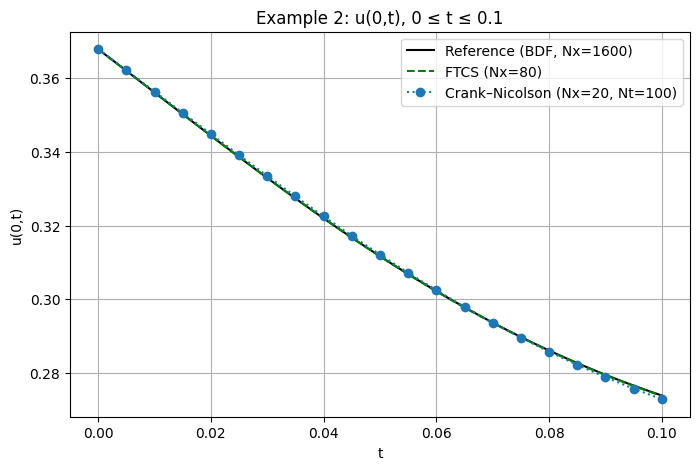

In [8]:
# 0 <= t <= 0.1
plt.figure(figsize=(8, 5))
plt.plot(t_eval[t_eval <= 0.1], ref_mid[t_eval <= 0.1], "k-",  label="Reference (BDF, Nx=1600)")
plt.plot(t_f[t_f <= 0.1],       m_f[t_f <= 0.1],        "g--", label="FTCS (Nx=80)")
plt.plot(t[t <= 0.1], U_CN[t <= 0.1, mid], "o:",        label="Crank–Nicolson (Nx=20, Nt=100)")
plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Example 2: u(0,t), 0 ≤ t ≤ 0.1")
plt.grid()
plt.legend()
plt.show()

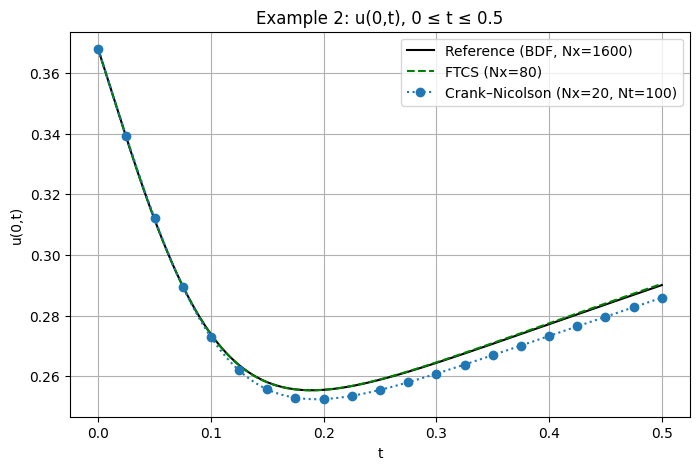

In [9]:
# 0 <= t <= 0.5
plt.figure(figsize=(8, 5))
plt.plot(t_eval, ref_mid, "k-",  label="Reference (BDF, Nx=1600)")
plt.plot(t_f,    m_f,     "g--", label="FTCS (Nx=80)")
plt.plot(t, U_CN[:, mid], "o:", markevery=5, label="Crank–Nicolson (Nx=20, Nt=100)")
plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Example 2: u(0,t), 0 ≤ t ≤ 0.5")
plt.grid()
plt.legend()
plt.show()

## 7. Error at $t=0.5$

The reference solution at $t=0.5$ is interpolated onto the CN grid and the maximum absolute error is computed.

In [10]:
xr_ref, sol_ref = reference_solution(Nx_ref=1600, T=T, t_eval=[T])

dxr = xr_ref[1] - xr_ref[0]
u_ref = np.empty(len(xr_ref))
u_ref[1:-1] = sol_ref.y[:, -1]
u_ref[0]  = (4*u_ref[1]  - u_ref[2]  - 2*dxr*g_left)  / 3
u_ref[-1] = (4*u_ref[-2] - u_ref[-3] + 2*dxr*g_right) / 3

print("Reference solution computed at t =", T)
print("Reference grid points:", len(xr_ref))
print("dx_ref =", dxr)

# Error for the single run above (Nx=20, Nt=100)
max_error = np.max(np.abs(U_CN[-1] - np.interp(x, xr_ref, u_ref)))
print(f"\nMaximum absolute error (Nx=20, Nt=100) = {max_error:.6e}")

Reference solution computed at t = 0.5
Reference grid points: 1601
dx_ref = 0.0012499999999999734

Maximum absolute error (Nx=20, Nt=100) = 8.652531e-03


## 8. Grid refinement

The time step is refined together with the space step, $\Delta t\approx 0.2\,\Delta x$, so that spatial and temporal errors decrease together.

In [11]:
Nx_values = [5, 10, 15, 20, 25, 30, 40, 60, 80, 100, 120]
errors = []

print(f"{'Nx':>4}  {'Nt':>4}  {'Max abs error':>14}")
print("-" * 28)

for Nx_k in Nx_values:
    Nt_k = int(np.ceil(T / (0.2 * (2.0 / Nx_k))))        # dt ≈ 0.2 dx
    xk, tk, Uk, *_ = solve_cn(Nx=Nx_k, Nt=Nt_k, T=T)
    err = np.max(np.abs(Uk[-1] - np.interp(xk, xr_ref, u_ref)))
    errors.append(err)
    print(f"{Nx_k:>4}  {Nt_k:>4}  {err:>14.6e}")

Nx_values = np.array(Nx_values)
errors    = np.array(errors)
dx_values = 2.0 / Nx_values

  Nx    Nt   Max abs error
----------------------------
   5     7    9.777857e-02
  10    13    2.742329e-02
  15    19    1.442350e-02
  20    25    8.800590e-03
  25    32    5.884815e-03
  30    38    4.706630e-03
  40    50    3.403359e-03
  60    75    2.154072e-03
  80   100    1.573061e-03
 100   125    1.240616e-03
 120   150    1.024181e-03


In [12]:
# Observed convergence order  p = log(E1/E2) / log(dx1/dx2)
print("Observed convergence orders:")
for i in range(len(errors) - 1):
    p = np.log(errors[i] / errors[i+1]) / np.log(dx_values[i] / dx_values[i+1])
    print(f"  Nx = {Nx_values[i]:>3} -> {Nx_values[i+1]:>3}:  p = {p:.4f}")

Observed convergence orders:
  Nx =   5 ->  10:  p = 1.8341
  Nx =  10 ->  15:  p = 1.5847
  Nx =  15 ->  20:  p = 1.7173
  Nx =  20 ->  25:  p = 1.8035
  Nx =  25 ->  30:  p = 1.2253
  Nx =  30 ->  40:  p = 1.1270
  Nx =  40 ->  60:  p = 1.1281
  Nx =  60 ->  80:  p = 1.0927
  Nx =  80 -> 100:  p = 1.0640
  Nx = 100 -> 120:  p = 1.0515


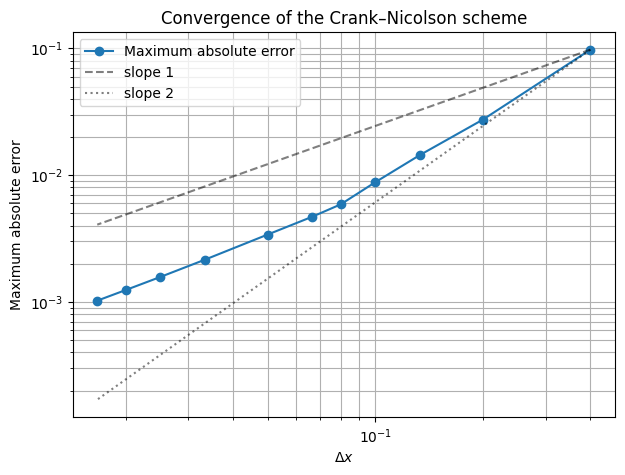

In [13]:
plt.figure(figsize=(7, 5))
plt.loglog(dx_values, errors, "o-", label="Maximum absolute error")

# reference slopes, anchored at the coarsest point
plt.loglog(dx_values, errors[0]*(dx_values/dx_values[0])**1, "k--", alpha=0.5, label="slope 1")
plt.loglog(dx_values, errors[0]*(dx_values/dx_values[0])**2, "k:",  alpha=0.5, label="slope 2")

plt.xlabel(r"$\Delta x$")
plt.ylabel("Maximum absolute error")
plt.title("Convergence of the Crank–Nicolson scheme")
plt.grid(True, which="both")
plt.legend()
plt.show()

## 9. Discussion

The Crank–Nicolson solution agrees with both the FTCS solution and the high-resolution reference: for example $u(0,0.1)\approx0.2729$ (reference $0.2739$) and $u(0,0.5)\approx0.2859$ (reference $0.2901$) for $N_x=20,\,N_t=100$.

The maximum error at $t=0.5$ decreases steadily as the grid is refined, from about $2.74\times10^{-2}$ at $N_x=10$ to about $1.02\times10^{-3}$ at $N_x=120$, so the scheme converges.

The observed order is

$$p=\frac{\log(E_1/E_2)}{\log(\Delta x_1/\Delta x_2)}$$

and falls from about $1.8$ on the coarsest grids to about $1.05$ at $N_x\approx100$–$120$. Although the diffusion term is second-order Crank–Nicolson, the nonlinear reaction term is treated **explicitly**, which is only first-order accurate in time, and $\Delta t$ was refined as $\Delta t\approx0.2\,\Delta x$. The observed rate therefore reflects the combined space–time error and tends towards first-order behaviour, rather than the formal order of the Crank–Nicolson diffusion discretisation alone.

A fully second-order-in-time scheme would require the reaction term to be treated implicitly (e.g. Newton iteration) or by a second-order splitting.